In [ ]:
import utils
import pandas as pd
import matplotlib.pyplot as plt
import importlib

In [205]:
import dashboard as ds
importlib.reload(ds)

<module 'dashboard' from 'd:\\Universidad\\TPE - Ciencia de datos\\dashboard.py'>

In [ ]:
importlib.reload(utils)

In [ ]:
data_path = 'results.csv'
df = pd.read_csv(data_path, low_memory=False)

meta_path = 'schema.csv'
metadatos = pd.read_csv(meta_path)

<h1 style="color: orange;">Analisis Exploratorio

<h3 style="color: violet;">Reduccion de variables a considerar durante el analisis de datos

In [ ]:
clean_metadatos = metadatos

<h4><u>Variables de respuesta libre

Analizando el dataset de metadatos, vemos que son aquellas que tienen como tipo de respuesta admitida ('type'):
- TE (Text Entry)
- RO (Ranking Order) con ('sub') = TEXT

In [ ]:
columns_save = [
    'WorkExp',
    'YearsCode',
    'ToolCountWork',
    'ToolCountPersonal',
    'CompTotal'
]
var_free = metadatos[(metadatos['type'] == 'TE') | (metadatos['sub'].str.contains('Text'))]
var_free = var_free[~var_free['qname'].isin(columns_save)] #salvamos aquellas que necesitamos
clean_metadatos.drop(var_free.index)
var_free[['qname', 'question', 'type', 'sub']].head(6)

Ademas, realizamos un promedio de porcentajes de valores nulos entre todas las columnas que descartamos y observamos que, en  promedio, el 84% de los valores de estas eran nulos. Observado tambien en el grafico de torta

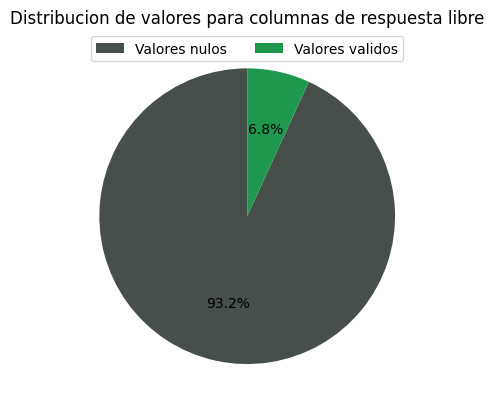

In [ ]:
utils.graficar_nulos(
    df,
    var_free['qname'].tolist(),
    labels=['Valores nulos', 'Valores validos'],
    title='Distribucion de valores para columnas de respuesta libre',
    colors=["#474f4a", '#1e984f']
)

In [ ]:
j = percentage_null = 0
cant_null = cant_not_null = 0
for i in var_free['qname']:
    cant_null += df[i].isna().sum()
    cant_not_null += df[i].notna().sum()
    percentage_null += df[i].isna().mean()
    j += 1

percentage_null /= j
print(f"Promedio: {percentage_null} - Cantidad nulos: {cant_null} - Cantidad no nulos: {cant_not_null} - Total: {cant_null + cant_not_null}")

In [ ]:
df = df.drop(columns=var_free['qname'].to_list(), errors="ignore")

<h4><u>Variables asociadas al uso de StackOverflow

Analizando el dataset de metadatos, vemos que son aquellas que comienzan con 'SO' en el nombre de variable

In [ ]:
var_SO = metadatos[metadatos['qname'].str.startswith('SO')]
clean_metadatos.drop(var_SO.index)
df = df.drop(columns=var_SO['qname'].to_list(), errors="ignore")
var_SO[['qname', 'question']].head(3)

<h3 style="color: violet;">Distribucion de variables

In [174]:
def histEs(bins=5):
    def draw(ax):
        comp = df['CompTotal'].dropna()
        limite = comp.quantile(0.85)

        comp[comp <= limite].hist(
            bins=bins,
            edgecolor='black',
            ax=ax
        )

        ax.set_title('CompTotal:85%')
        ax.set_xlabel('')
        ax.grid(False)
        ax.tick_params(axis="x", rotation=45)

    return ds.Chart(draw=draw)


<h4><u>Demografía y Perfil Laboral

In [264]:
dash = ds.Dashboard(columns=4, figsize=(20, 4))

In [261]:
def maping_and_add(col, values_change, min):
    values = df[col].value_counts().index.to_list()
    mapeo = {}
    for i, val in enumerate(values):
        if i == len(values_change): break
        mapeo[val] = values_change[i]
    dash.add.bar(df, col, min=min, cut=mapeo)
    #print(mapeo)

In [265]:
maping_and_add('MainBranch', [1, 2, 3, 4, 5, 6], min=2000)
maping_and_add('EdLevel', ['Bd', 'Md', 'CU', 'Ss', 'Pd', 'Ad', 'Othr', 'Ps'], min=2000)
maping_and_add('OrgSize', ['20-99', '100-499', '<20', '>10k', '1k-5k', '500-1k', 'Me', '5k-10k', 'DK'], min=2400)
maping_and_add('DevType', ['Fs', 'Be', 'Stud', 'Arch', 'Fe', 'd_e'], min=2400)
maping_and_add('RemoteWork', ['Remote', 'H_p', 'Person', 'H_r', 'Choice'], min=2400)
maping_and_add('NewRole', ['No', 'con_1', 'con_2', 'Yes_v', 'Yes_i'], min=2400)

In [220]:
values = df['MainBranch'].value_counts().index.to_list()
mapeo = {}
i = 1
for val in values:
    mapeo[val] = i
    i += 1
dash.add.bar(df, "MainBranch", min=2000, cut=mapeo)

In [221]:
values = df['EdLevel'].value_counts().index.to_list()
values_change = ['Bd', 'Md', 'CU', 'Ss', 'Pd', 'Ad', 'Othr', 'Ps']
mapeo = {}
for i, val in enumerate(values): mapeo[val] = values_change[i]
dash.add.bar(df, "EdLevel", min=2000, cut=mapeo)

In [266]:
#this
df['Employment'] = df['Employment'].replace('Independent contractor, freelancer, or self-employed', 'Independent')
dash.add.bar(df, "Employment", min=1000, cut=6)

In [ ]:
values = df['OrgSize'].value_counts().index.to_list()
values_change = ['20-99', '100-499', '<20', '>10k', '1k-5k', '500-1k', 'Me', '5k-10k', 'DK']
mapeo = {}
for i, val in enumerate(values): mapeo[val] = values_change[i]
dash.add.bar(df, "OrgSize", min=2400, cut=mapeo)
#df['OrgSize'].value_counts()
#mapeo

In [ ]:
values = df['DevType'].value_counts().index.to_list()
values_change = ['Fs', 'Be', 'Stud', 'Arch', 'Fe', 'd_e']
mapeo = {}
for i, val in enumerate(values):
    if i == len(values_change): break
    mapeo[val] = values_change[i]
dash.add.bar(df, "DevType", min=2400, cut=mapeo)
#df['OrgSize'].value_counts()
#mapeo

In [ ]:
values = df['RemoteWork'].value_counts().index.to_list()
values_change = ['Remote', 'H_p', 'Person', 'H_r', 'Choice']
mapeo = {}
for i, val in enumerate(values):
    if i == len(values_change): break
    mapeo[val] = values_change[i]
dash.add.bar(df, "RemoteWork", min=2400, cut=mapeo)
#df['OrgSize'].value_counts()
#mapeo

In [ ]:
values = df['NewRole'].value_counts().index.to_list()
values_change = ['No', 'consider_1', 'consider_2', 'Yes_v', 'Yes_i']
mapeo = {}
for i, val in enumerate(values):
    if i == len(values_change): break
    mapeo[val] = values_change[i]
dash.add.bar(df, "NewRole", min=2400, cut=mapeo)
#mapeo
#df['NewRole'].value_counts()

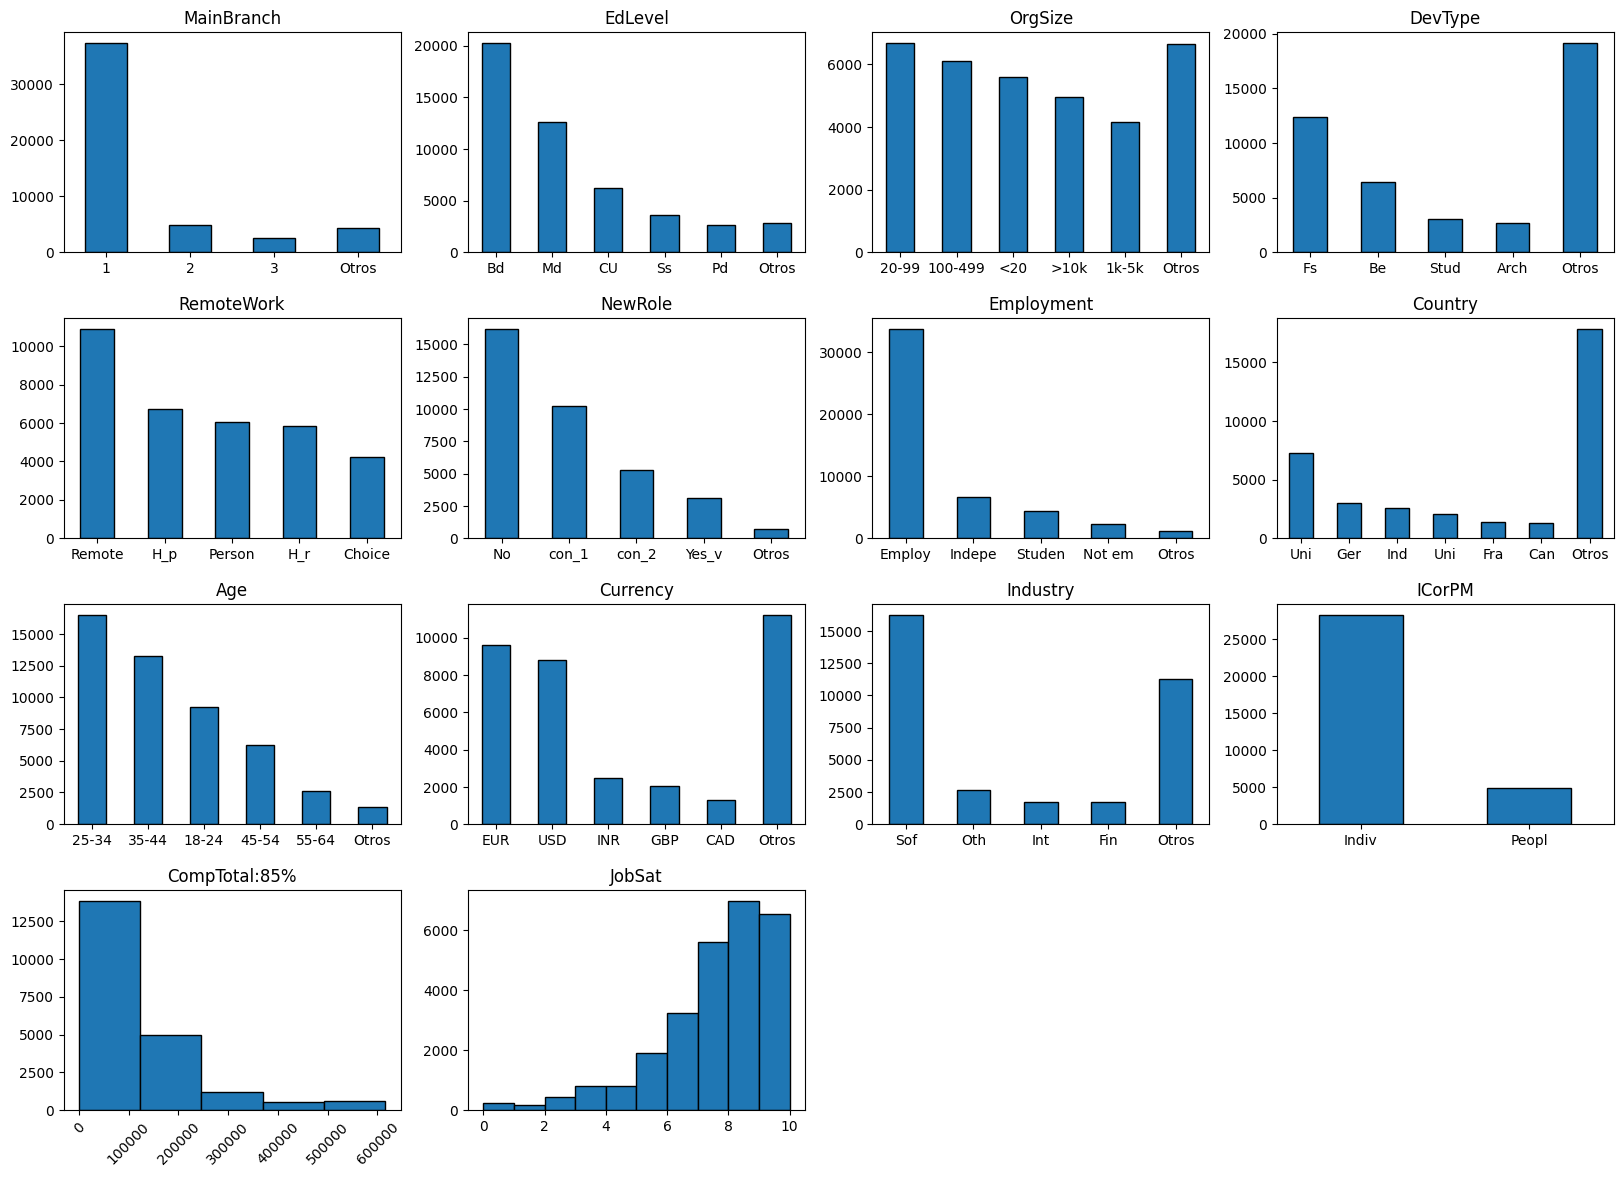

In [267]:
dash.add.bar(df, "Country", min=1000, cut=3)
dash.add.bar(df, "Age", min=2000, cut=' ')
dash.add.bar(df, "Currency", min=1000, cut=3)
dash.add.bar(df, "Industry", min=1500, cut=3)
dash.add.bar(df, "ICorPM", min=1500, cut=5)
dash.addChart(histEs(bins=5))
columnas = [
    'MainBranch',
    'Age',
    'Country',
    'Currency',
    'EdLevel',
    'Employment',
    'EmploymentAddl',
    'Industry',
    'OrgSize',
    'DevType',
    'ICorPM',
    'RemoteWork',
    'JobSat',
    'NewRole'
]
dash.add.multiple_hist(df, columnas, bins=10)

dash.show()